In [49]:
import os
import re
import pandas as pd
from io import StringIO
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

## Caricamento file di SRSR-D
Carico i dati e li salvo in un dizionario, carico solo le righe contenenti il beam pattern

In [50]:
folder_path = './dati'
data_dict = {}

# Regex per estrarre la frequenza (cifra tra '_' e 'k')
freq_pattern = re.compile(r'_(\d+)k')

for filename in os.listdir(folder_path):
    if filename.endswith(".sr"):
        # extracting the  
        match = freq_pattern.search(filename)
        if match:
            frequenza_mhz = int(int(match.group(1))/10e5)
            file_full_path = os.path.join(folder_path, filename)
            

            with open(file_full_path, 'r') as f:
                lines = f.readlines()
            
            selected_lines = lines[-369:-8] 

            if selected_lines:
    
                reversed_lines = list(reversed(selected_lines[1:]))
                combined_list = selected_lines# reversed_lines + selected_lines
                data_string = "".join(combined_list)
                
                
                
                # Creiamo il DataFrame dividendo per spazi (sep='\s+')
                df = pd.read_csv(
                    StringIO(data_string), 
                    sep='\s+', 
                    header=None, 
                    names=['E_plane_re', 'E_plane_im', 'H_plane_re', 'H_plane_im']
                )                
                # Salviamo il DataFrame nel dizionario usando la frequenza come chiave
                data_dict[frequenza_mhz] = df


<>:32: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_8929/2599956581.py:32: SyntaxWarning: invalid escape sequence '\s'
  sep='\s+',


## Esempio di potenza

     E_plane_re  E_plane_im  H_plane_re  H_plane_im
0     -3.669570   -5.288460   -3.669570   -5.288460
1     -3.666680   -5.284050   -3.666420   -5.283910
2     -3.658030   -5.270830   -3.656990   -5.270260
3     -3.643650   -5.248870   -3.641330   -5.247600
4     -3.623620   -5.218280   -3.619490   -5.216030
..          ...         ...         ...         ...
356    0.012222   -0.009073   -0.012949    0.010568
357    0.012712   -0.009931   -0.013123    0.010786
358    0.013064   -0.010559   -0.013248    0.010944
359    0.013277   -0.010942   -0.013323    0.011039
360    0.013348   -0.011071   -0.013348    0.011071

[361 rows x 4 columns]


Text(0.5, 0, 'Angolo (?)')

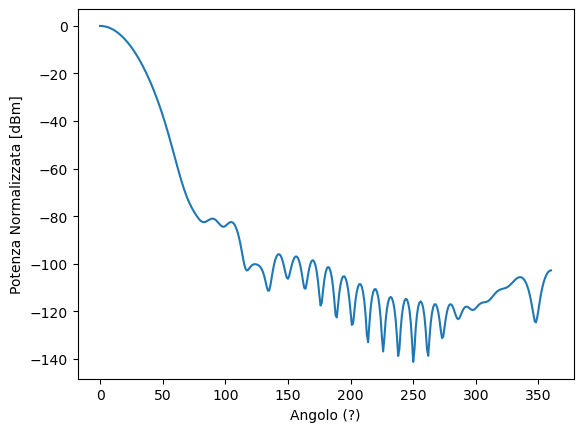

In [51]:
df = data_dict[25]
print(df)

E = df["E_plane_re"]**2+df["E_plane_im"]**2

P = E/E.max()

P_dB = 20*np.log10(P)

#invertion of the specular part e concatenation for plotting
#P_dB =list(reversed(P_dB))+list(P_dB)

plt.plot(P_dB)
plt.ylabel("Potenza Normalizzata [dBm]")
plt.xlabel("Angolo (?)")

<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_8929/3918663535.py:4: SyntaxWarning: invalid escape sequence '\s'
  sep='\s+',


Text(0.5, 0, 'Angolo (?)')

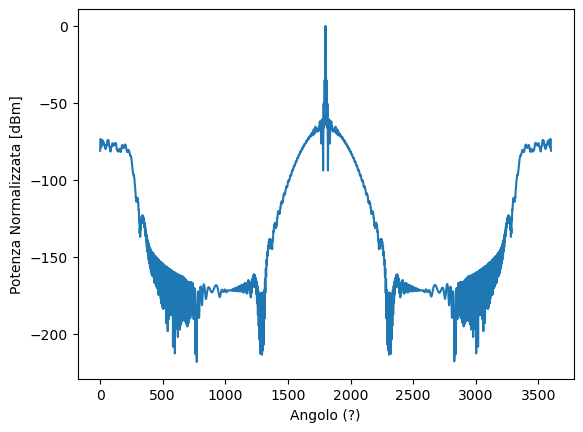

In [52]:
#CARICAMENTO DELLE COMPONENTI DI GRASP
spherical_cut = pd.read_csv(
                    "spherical_cut.cut", 
                    sep='\s+', 
                    header=None, 
                    names=['E_plane_re', 'E_plane_im', 'H_plane_re', 'H_plane_im'],
                    skiprows = [0,1],
                    nrows = 3601
                )        


E = spherical_cut["E_plane_re"]**2+spherical_cut["E_plane_im"]**2

P = E/E.max()

P_dB = 20*np.log10(P)

plt.plot(P_dB)
plt.ylabel("Potenza Normalizzata [dBm]")
plt.xlabel("Angolo (?)")

# Generazione di un piano di taglio qualunque

In [53]:
def ref_cross_polariz(E_p,H_p,phy):
    Ex = E_p*np.sin(phy)**2+ H_p*np.cos(phy)**2
    Ey = (E_p- H_p)*np.cos(phy)*np.sin(phy)

    return Ex,Ey

In [55]:
num_cut = 17 # number of cuts between start and end phy
start_phy = 0
end_phy = 360
start_theta = 0
n_thetas = len(data_dict[next(iter(data_dict))])
delta_theta = 0.5 # the same of sr-sr




cuts_phy = np.linspace(start_phy,end_phy, num_cut)

folder_path = "spherical_cuts_0_180"

if not os.path.exists(folder_path):
    os.makedirs(folder_path)
    print("Creating Folder ...")
else:
    print("Folder alredy there!")

for key in data_dict.keys():

    # createa anew file for every frequency
    file_name = f"spherical_cut_{str(key)}.cut"
    data = data_dict[key]
    path_tot = folder_path +"/"+file_name

    with open(path_tot, "w") as f:

        for phy in cuts_phy[:-1]:#not closing the circle
            f.write(f"Field data in cuts \n")

            f.write(f"{start_theta:.15E} {delta_theta:.15E} {n_thetas} {phy:.15E}    3    1    2\n")
            E_plane_re,H_plane_re = ref_cross_polariz(data['E_plane_re'],data['H_plane_re'],phy)
            E_plane_im,H_plane_im = ref_cross_polariz(data['E_plane_im'],data['H_plane_im'],phy)

            for e_re, e_im, h_re, h_im in zip(E_plane_re, E_plane_im, H_plane_re, H_plane_im):
                f.write(f"{e_re:.15E}  {e_im:.15E}  {h_re:.15E}  {h_im:.15E}\n")


    
    



Folder alredy there!
